# CNN pequeña desde cero · Benchmark de deep learning con pocos datos

CNN de 3 bloques convolucionales (Conv → ReLU → MaxPool) y un clasificador denso, con 0.6 a 2.2 M de parámetros según el dataset. Se entrena desde pesos aleatorios, **sin transfer learning**, y sirve como línea base. Entrada de 32×32 en CIFAR-10 y de 64×64 en Oxford Pet y Caltech-101.

Este notebook entrena y evalúa el modelo en **CIFAR-10**, **Oxford-IIIT Pet** y **Caltech-101** con 500, 1.000 y 2.000 imágenes de entrenamiento y 3 semillas por configuración, en dos fases:

- **Fase 1 (baseline):** sin data augmentation (sección 9).
- **Fase 2:** RandAugment + MixUp/CutMix (sección 10).

Los cuatro notebooks de modelos comparten el mismo protocolo (splits, motor de entrenamiento y métricas), así que sus resultados son directamente comparables. Cada experimento se guarda como una fila en `resultados/resultados_cnn/resultados_cnn.csv`, y la comparación entre modelos está en `05_analisis_conjunto.ipynb`.

**Ejecución:** correr las celdas en orden. Los experimentos que ya están en el CSV se cargan en vez de reentrenarse (`SALTAR_SI_EXISTE = True`).

> **Nota sobre el learning rate.** Se acordó un learning rate más alto (1e-3) para la CNN por no estar preentrenada, pero en `LEARNING_RATES` (sección 1) la clave `"cnn"` quedó duplicada (`{"cnn": 1e-3, ..., "cnn": 1e-4}`) y en Python prevalece el último valor. Por lo tanto, **todos los resultados de la CNN, en ambas fases, se obtuvieron con learning rate 1e-4**. El código se deja tal como se ejecutó. Esto se verificó reentrenando un experimento (CIFAR-10, 1.000 imágenes, semilla 42): con 1e-4 se reproduce el perfil del benchmark (train_acc ≈ 0.49, brecha ≈ 7 pts), mientras que con 1e-3 la CNN llega a train_acc 0.85 y test_acc 0.46 (brecha ≈ 39 pts). Por eso el *underfitting* que muestra la CNN se debe en buena parte al learning rate bajo (ver Limitaciones en el README).

### Ejecución en Google Colab

El notebook detecta si está en Colab y se adapta:

1. Activar la GPU: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*.
2. Crear la carpeta `Proyecto_DL` en Google Drive. Ahí se guardan los resultados y las predicciones, para que no se pierdan si la sesión se desconecta.
3. Ejecutar las celdas en orden y aceptar el permiso para montar Drive. Los datasets se descargan automáticamente la primera vez.

Si la sesión se corta a mitad de una grilla, al volver a ejecutar el notebook se retoma solo lo que falta.

## 1. Configuración

Rutas y parámetros del experimento. Las semillas, los tamaños de entrenamiento, las épocas y el batch size son los mismos para los cuatro modelos, para que los resultados sean comparables.

In [14]:
from pathlib import Path

# detecta si estamos en google colab
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # colab: montar drive para que resultados y predicciones no se pierdan
    # al desconectarse la sesion. los datasets se descargan solos (rapido).
    from google.colab import drive
    drive.mount("/content/drive")
    # carpeta del proyecto en Google Drive
    PROYECTO_DRIVE = Path("/content/drive/MyDrive/Proyecto_DL")
    DATA_ROOT = PROYECTO_DRIVE / "datos"       # torchvision baja aca la 1a vez
    RESULTS_DIR = PROYECTO_DRIVE / "resultados" / "resultados_cnn"
    DESCARGAR = True                            # colab descarga los datos solo
else:
    # local: datasets en ../datos (ver datos/README.md)
    DATA_ROOT = Path("../datos")
    RESULTS_DIR = Path("../resultados") / "resultados_cnn"
    DESCARGAR = False   # los datos ya están en disco

print("Entorno:", "Colab" if EN_COLAB else "Local", "| descargar datos:", DESCARGAR)

# Parámetros comunes a los cuatro modelos (iguales para que sean comparables)

# 3 semillas para reportar media ± std
SEEDS = [42, 123, 2024]

# Tamaños de subset de ENTRENAMIENTO (solo train; val y test son fijos)
TRAIN_SIZES = [500, 1000, 2000]
VAL_SIZE = 1000
TEST_SIZE = 2000        # CIFAR podría usar su test oficial; aquí test fijo estratificado


# pet solo tiene ~3680 imgs: con test=2000+val=1000 no cabia train=2000.
# bajo test/val solo para pet.
VAL_SIZE_POR_DATASET  = {"pet": 500}
TEST_SIZE_POR_DATASET = {"pet": 1000}

def val_size_de(dataset_name):
    return VAL_SIZE_POR_DATASET.get(dataset_name, VAL_SIZE)

def test_size_de(dataset_name):
    return TEST_SIZE_POR_DATASET.get(dataset_name, TEST_SIZE)

# Hiperparámetros comunes (sin ajuste fino por modelo)
EPOCHS = 20

# workers para cargar datos. En Colab/Linux funcionan; en Windows
# (VS Code/Jupyter) el multiprocessing se cuelga -> usar 0 alli.
NUM_WORKERS = 2 if EN_COLAB else 0
BATCH_SIZE = 32
# Nota: la clave "cnn" está duplicada y Python usa el último valor, así que la CNN
# se entrenó con 1e-4 (ver la nota al inicio del notebook).
LEARNING_RATES = {"cnn": 1e-3, "resnet18": 1e-4, "deit": 1e-4, "cnn": 1e-4}
DEFAULT_LR = 1e-4

# Fase 1 = sin augmentation
USE_AUGMENTATION_DEFAULT = False

DATASETS = ["cifar10", "pet", "caltech101"]
NUM_CLASSES = {"cifar10": 10, "pet": 37, "caltech101": 101}

print("Config cargada. DATA_ROOT =", DATA_ROOT.resolve())

Entorno: Local | descargar datos: False
Config cargada. DATA_ROOT = ..\datos


### Verificación de los datasets

Revisa que las tres carpetas de datos tengan la estructura que espera torchvision (✓ / ✗), sin entrenar nada.

In [15]:
# Chequeo de estructura de datasets (no entrena, solo verifica carpetas)
def verificar_datasets():
    base = DATA_ROOT
    print(f"Revisando en: {base.resolve()}\n")
    ok_todo = True

    def check(nombre, ruta_relativa, es_carpeta=True):
        nonlocal ok_todo
        p = base / ruta_relativa
        existe = p.is_dir() if es_carpeta else p.is_file()
        marca = "OK " if existe else "FALTA"
        if not existe:
            ok_todo = False
        print(f"  [{marca}] {ruta_relativa}")
        return existe

    print("CIFAR-10")
    c = check("cifar-10", "cifar-10-batches-py")
    if c:
        check("cifar-10", "cifar-10-batches-py/data_batch_1", es_carpeta=False)
        check("cifar-10", "cifar-10-batches-py/test_batch", es_carpeta=False)

    print("\nOxford-IIIT Pet")
    check("pet", "oxford-iiit-pet/images")
    check("pet", "oxford-iiit-pet/annotations")

    print("\nCaltech-101")
    check("caltech", "caltech101/101_ObjectCategories")

    print("\n" + ("Todo listo, puedes entrenar." if ok_todo
                   else "Falta algo arriba; corrige y vuelve a correr esta celda."))
    return ok_todo


# en local verifica las carpetas manuales; en colab no aplica (torchvision
# descarga con su propia estructura), asi que se salta.
#if not EN_COLAB:
 #   verificar_datasets()
#else:
 #   print("En Colab: la verificación de carpetas manuales se omite "
  #        "(torchvision descarga los datos solo).")

### Caltech-101 desde el zip (Colab)

La descarga automática de Caltech-101 con torchvision falla con frecuencia. Si `caltech-101.zip` está en `Proyecto_DL/datos/` de Google Drive, esta celda lo deja en la estructura que espera torchvision (`datos/caltech101/101_ObjectCategories/`). Acepta tanto el zip oficial (que trae un `101_ObjectCategories.tar.gz` dentro) como un zip con las carpetas directamente, e ignora la carpeta `__MACOSX`. Si Caltech-101 ya está descomprimido, no hace nada.

In [16]:
# preparar caltech-101 desde el zip del drive (solo actua si hace falta)
import zipfile
import tarfile
import shutil


def preparar_caltech_desde_zip(zip_path, data_root):
    destino = Path(data_root) / "caltech101" / "101_ObjectCategories"

    # idempotente: si ya estan las ~101 carpetas de categorias, no hace nada
    if destino.is_dir() and sum(1 for p in destino.iterdir() if p.is_dir()) >= 100:
        print("Caltech ya esta en su lugar:", destino)
        return True

    zip_path = Path(zip_path)
    if not zip_path.exists():
        print("No encuentro el zip:", zip_path)
        print("Subelo a esa ruta de tu Drive o corrige ZIP_CALTECH.")
        return False

    tmp = Path(data_root) / "_tmp_caltech"
    if tmp.exists():
        shutil.rmtree(tmp)
    tmp.mkdir(parents=True)

    def _untar(ruta_tar, a_donde):
        with tarfile.open(ruta_tar) as t:
            try:
                t.extractall(a_donde, filter="data")   # python >= 3.12
            except TypeError:
                t.extractall(a_donde)                  # python mas viejo

    with zipfile.ZipFile(zip_path) as z:
        nombres = z.namelist()
        print("Primeras rutas internas del zip (diagnostico):")
        for n in nombres[:6]:
            print("   ", n)

        utiles = [n for n in nombres if "__MACOSX" not in n]
        # caso oficial: el zip trae 101_ObjectCategories.tar.gz adentro
        tars = [n for n in utiles if n.endswith("101_ObjectCategories.tar.gz")]
        # caso alternativo: el zip trae las carpetas de imagenes directamente
        directos = [n for n in utiles if "101_ObjectCategories/" in n]

        if tars:
            print("Detectado zip oficial (tar.gz interno). Extrayendo...")
            z.extract(tars[0], tmp)
            _untar(tmp / tars[0], tmp / "untar")
            origen = next(p for p in (tmp / "untar").rglob("101_ObjectCategories")
                          if p.is_dir())
        elif directos:
            print(f"Detectadas carpetas directas ({len(directos)} entradas). "
                  "Extrayendo...")
            for n in directos:
                z.extract(n, tmp)
            origen = next(p for p in tmp.rglob("101_ObjectCategories")
                          if p.is_dir())
        else:
            print("El zip no contiene 101_ObjectCategories. Revisa su contenido.")
            shutil.rmtree(tmp)
            return False

    destino.parent.mkdir(parents=True, exist_ok=True)
    if destino.exists():
        shutil.rmtree(destino)
    shutil.move(str(origen), str(destino))
    shutil.rmtree(tmp)

    n_clases = sum(1 for p in destino.iterdir() if p.is_dir())
    print(f"Listo: {destino} con {n_clases} categorias.")
    return True


ZIP_CALTECH = DATA_ROOT / "caltech-101.zip"
preparar_caltech_desde_zip(ZIP_CALTECH, DATA_ROOT)

Caltech ya esta en su lugar: datos\caltech101\101_ObjectCategories


True

## 2. Dispositivo (GPU/CPU) y reproducibilidad

Usa GPU si hay (`cuda`), si no CPU. No hay que configurar nada; en CPU corre igual, solo más lento. `fijar_semilla` bloquea toda la aleatoriedad para que dos corridas con la misma semilla den el mismo resultado.

In [17]:
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim


def get_device():
    """cuda si está disponible, si no cpu."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fijar_semilla(seed):
    """Fija python, numpy y torch (CPU+GPU) para reproducibilidad total."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


DEVICE = get_device()
print("Dispositivo:", DEVICE)

Dispositivo: cuda


## 3. Métricas

`accuracy` y `f1_macro`. El F1-macro es clave en Caltech-101: promedia el F1 de cada clase por igual, así que una clase con 40 imágenes pesa lo mismo que una con 800. `overfitting_gap` = (train_acc − test_acc) × 100 mide el sobreajuste.

In [18]:
from collections import defaultdict


def accuracy(y_true, y_pred):
    if len(y_true) == 0:
        return 0.0
    return sum(1 for t, p in zip(y_true, y_pred) if t == p) / len(y_true)


def f1_macro(y_true, y_pred, num_classes):
    """Promedio simple del F1 por clase. Equivale a sklearn average='macro'."""
    tp = defaultdict(int); fp = defaultdict(int); fn = defaultdict(int)
    for t, p in zip(y_true, y_pred):
        if t == p:
            tp[t] += 1
        else:
            fp[p] += 1; fn[t] += 1
    f1s = []
    for c in range(num_classes):
        prec = tp[c] / (tp[c] + fp[c]) if (tp[c] + fp[c]) > 0 else 0.0
        rec  = tp[c] / (tp[c] + fn[c]) if (tp[c] + fn[c]) > 0 else 0.0
        f1s.append(2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0)
    return sum(f1s) / len(f1s) if f1s else 0.0


def overfitting_gap(train_acc, test_acc):
    return (train_acc - test_acc) * 100.0

## 4. Datos y splits reproducibles

La pieza crítica para la comparabilidad. Garantiza:

1. Los índices de train/val/test son idénticos para los cuatro modelos (dependen solo de dataset, tamaño y semilla).
2. **Val y test se mantienen fijos**: al variar el tamaño de train (500/1000/2000), no cambian. Así la curva accuracy-vs-tamaño mide solo el efecto de tener más datos de entrenamiento.
3. Cada modelo recibe los mismos índices pero aplica su propia transform.

Caltech-101 recibe trato especial: se excluye la clase basura `BACKGROUND_Google` y se fuerza RGB (hay imágenes en escala de grises).

In [19]:
from torch.utils.data import Subset, DataLoader
from torchvision import datasets


def _etiquetas_de(dataset):
    """Labels sin decodificar imágenes cuando se puede (importa en Pet/Caltech)."""
    if getattr(dataset, "targets", None) is not None:
        return [int(x) for x in dataset.targets]
    if hasattr(dataset, "y"):
        return [int(x) for x in dataset.y]
    if hasattr(dataset, "_labels"):
        return [int(x) for x in dataset._labels]
    return [int(dataset[i][1]) for i in range(len(dataset))]


def _split_estratificado(labels, n_train, n_val, n_test, seed, num_classes):
    # reparte train/val/test estratificado por clase, sin solapamiento.
    # el puntero por clase evita entregar el mismo indice dos veces.
    idx_por_clase = defaultdict(list)
    for idx, lab in enumerate(labels):
        idx_por_clase[lab].append(idx)

    rng = random.Random(seed)
    for c in idx_por_clase:
        rng.shuffle(idx_por_clase[c])

    # Puntero por clase: avanza globalmente, nunca reutiliza un índice.
    punteros = {c: 0 for c in idx_por_clase}

    def _tomar(c, k):
        p = punteros[c]
        disp = idx_por_clase[c][p:p + k]
        punteros[c] = p + len(disp)
        return disp

    cuota_test  = max(1, n_test  // num_classes)
    cuota_val   = max(1, n_val   // num_classes)
    cuota_train = max(1, n_train // num_classes)

    # Orden: test -> val -> train. Cada uno consume del puntero global.
    test_idx, val_idx, train_idx = [], [], []
    for c in sorted(idx_por_clase):
        test_idx += _tomar(c, cuota_test)
    for c in sorted(idx_por_clase):
        val_idx += _tomar(c, cuota_val)
    for c in sorted(idx_por_clase):
        train_idx += _tomar(c, cuota_train)

    # Completado: si por división entera faltan para llegar al tamaño exacto,
    # se toma de un pool GLOBAL de lo que quede sin usar (respetando punteros),
    # rellenando en orden test -> val -> train y quitando del pool lo asignado.
    def _pool_restante():
        pool = []
        for c in sorted(idx_por_clase):
            pool += idx_por_clase[c][punteros[c]:]
            punteros[c] = len(idx_por_clase[c])  # marcar como consumido
        rng.shuffle(pool)
        return pool

    pool = _pool_restante()
    pos = 0
    def _completar(actual, objetivo):
        nonlocal pos
        faltan = objetivo - len(actual)
        if faltan > 0:
            actual += pool[pos:pos + faltan]
            pos += faltan
        return actual

    test_idx  = _completar(test_idx, n_test)
    val_idx   = _completar(val_idx, n_val)
    train_idx = _completar(train_idx, n_train)

    assert not (set(train_idx) & set(val_idx)),  "train/val se solapan"
    assert not (set(train_idx) & set(test_idx)), "train/test se solapan"
    assert not (set(val_idx)   & set(test_idx)), "val/test se solapan"
    return train_idx, val_idx, test_idx

In [20]:
def _excluir_clase_basura(ds, labels):
    """Caltech101: quita 'BACKGROUND_Google' y reindexa clases a 0..100."""
    categorias = getattr(ds, "categories", None)
    if categorias is None or "BACKGROUND_Google" not in categorias:
        return ds, labels
    basura_id = categorias.index("BACKGROUND_Google")
    buenos = [i for i, lab in enumerate(labels) if lab != basura_id]
    viejos = sorted({lab for lab in labels if lab != basura_id})
    remap = {v: n for n, v in enumerate(viejos)}
    return Subset(ds, buenos), [remap[labels[i]] for i in buenos]


def _cargar_dataset_base(dataset_name, transform):
    root = str(DATA_ROOT)
    if dataset_name == "cifar10":
        ds = datasets.CIFAR10(root=root, train=True, download=DESCARGAR, transform=transform)
    elif dataset_name == "pet":
        ds = datasets.OxfordIIITPet(root=root, split="trainval",
                                    target_types="category",
                                    download=DESCARGAR, transform=transform)
    elif dataset_name == "caltech101":
        ds = datasets.Caltech101(root=root, target_type="category",
                                 download=DESCARGAR, transform=transform)
    else:
        raise ValueError(f"Dataset no soportado: {dataset_name}")

    labels = _etiquetas_de(ds)
    if dataset_name == "caltech101":
        ds, labels = _excluir_clase_basura(ds, labels)
    return ds, labels


def obtener_loaders(dataset_name, transform_factory, train_size, seed, use_aug=False):
    # val y test no dependen de train_size, solo crece train.
    #
    # FASE 2 (clave de correctitud): la augmentation a nivel imagen
    # (RandAugment) SOLO puede tocar el conjunto de ENTRENAMIENTO. Por eso
    # esta funcion recibe el FACTORY de la transform (no una transform ya
    # construida) y arma DOS:
    #   - train_tf: con augment si use_aug=True  (train=use_aug)
    #   - eval_tf : SIEMPRE sin augment          (train=False) -> val/test limpios
    # Con aug se cargan dos instancias del dataset (una por transform);
    # indexar la misma posicion en ambas apunta a la misma imagen porque la
    # carga es determinista, asi que los splits siguen alineados. En baseline
    # (use_aug=False) train_tf == eval_tf y se reutiliza UNA sola instancia:
    # bit-identico a la Fase 1. (Costo del camino aug: doble metadata; las
    # imagenes se cargan perezosamente, salvo CIFAR que duplica su array en
    # RAM, ~180 MB extra: aceptable en Colab.)
    num_classes = NUM_CLASSES[dataset_name]

    train_tf = transform_factory(dataset_name, train=use_aug)
    eval_tf  = transform_factory(dataset_name, train=False)

    if use_aug:
        ds_train, labels = _cargar_dataset_base(dataset_name, train_tf)
        ds_eval,  _      = _cargar_dataset_base(dataset_name, eval_tf)
    else:
        # baseline: una sola instancia con la transform de eval (sin aug)
        ds_train, labels = _cargar_dataset_base(dataset_name, eval_tf)
        ds_eval = ds_train

    train_idx, val_idx, test_idx = _split_estratificado(
        labels, train_size, val_size_de(dataset_name), test_size_de(dataset_name), seed, num_classes)

    nw  = NUM_WORKERS   # configurable desde la celda 3 (0 en Windows)
    pin = DEVICE.type == "cuda"

    # --- FASE 2 (sección 10): el collate de MixUp/CutMix (definido recién en
    #     la sección 10, al final) se engancha SOLO al train_loader y SOLO
    #     con use_aug=True. val/test nunca lo reciben (no se evalua mezclado).
    #     Con use_aug=False -> collate=None = comportamiento por defecto.
    if use_aug:
        if "mixup_cutmix_collate" not in globals():
            raise RuntimeError(
                "use_aug=True necesita el collate de MixUp/CutMix: "
                "corre primero las celdas de la sección 10 (FASE 2).")
        collate_train = mixup_cutmix_collate
    else:
        collate_train = None

    train_loader = DataLoader(Subset(ds_train, train_idx), batch_size=BATCH_SIZE,
                              shuffle=True, num_workers=nw, pin_memory=pin,
                              collate_fn=collate_train)
    val_loader   = DataLoader(Subset(ds_eval, val_idx), batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=nw, pin_memory=pin)
    test_loader  = DataLoader(Subset(ds_eval, test_idx), batch_size=BATCH_SIZE,
                              shuffle=False, num_workers=nw, pin_memory=pin)

    info = {"n_train": len(train_idx), "n_val": len(val_idx),
            "n_test": len(test_idx), "num_classes": num_classes}
    return train_loader, val_loader, test_loader, info

## 5. Motor de entrenamiento

Todos los modelos se entrenan con el mismo motor: mismo optimizador (Adam), misma pérdida (CrossEntropy), misma lógica de época. Solo cambian la arquitectura y la transform. El test se evalúa **una sola vez al final** (en la sección de corrida), no durante el entrenamiento.

In [21]:
@torch.no_grad()
def evaluar(modelo, loader, device):
    """Devuelve (acc, y_true, y_pred). Las listas permiten calcular F1-macro."""
    modelo.eval()
    y_true, y_pred = [], []
    correctos, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = modelo(x).argmax(1)
        correctos += (pred == y).sum().item()
        total += y.size(0)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())
    return (correctos / total if total else 0.0), y_true, y_pred


def entrenar(modelo, train_loader, val_loader, lr, epochs, device,
             nombre="modelo", verbose=True):
    """Entrena y devuelve dict con train_acc_final, historial y train_time_s.

    Soporta dos formatos de batch del train_loader:
      - (x, y)                -> Fase 1 baseline, loss normal.
      - (x, y_a, y_b, lam)    -> Fase 2 con MixUp/CutMix (soft targets):
                                 loss = lam*CE(out,y_a) + (1-lam)*CE(out,y_b).
    Detecta el formato mirando cuántos elementos trae el batch, así la MISMA
    función sirve para ambas fases sin flags extra. Con MixUp la etiqueta no
    es única, por eso train_acc se mide contra y_a (referencia aproximada);
    el número que importa para el paper sigue siendo test_acc, que se calcula
    aparte con evaluar() sobre datos sin mezclar."""
    modelo = modelo.to(device)
    optimizer = optim.Adam(modelo.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    historial = {"train_loss": [], "train_acc": [], "val_acc": []}
    t0 = time.time()

    for epoca in range(epochs):
        modelo.train()
        loss_total, correctos, total = 0.0, 0, 0
        for batch in train_loader:
            # --- FASE 2 (sección 10): batch de 4 = viene del collate
            #     MixUp/CutMix definido en la sección 10.
            #     batch de 2 = baseline de siempre.
            if len(batch) == 4:
                x, y_a, y_b, lam = batch
                x, y_a, y_b = x.to(device), y_a.to(device), y_b.to(device)
                y_ref = y_a          # referencia para train_acc
            else:
                x, y = batch
                x, y = x.to(device), y.to(device)
                y_a = y_b = y
                lam = 1.0
                y_ref = y

            optimizer.zero_grad()
            out = modelo(x)
            # con lam=1.0 (baseline) esto es exactamente CE(out, y):
            # loss = 1.0*CE(out,y) + 0.0*CE(out,y) -> idéntico al original.
            loss = lam * criterion(out, y_a) + (1.0 - lam) * criterion(out, y_b)
            loss.backward()
            optimizer.step()

            loss_total += loss.item() * x.size(0)
            correctos += (out.argmax(1) == y_ref).sum().item()
            total += x.size(0)

        train_loss = loss_total / total
        train_acc = correctos / total
        val_acc, _, _ = evaluar(modelo, val_loader, device)
        historial["train_loss"].append(train_loss)
        historial["train_acc"].append(train_acc)
        historial["val_acc"].append(val_acc)

        if verbose:
            print(f"[{nombre}] Época {epoca+1}/{epochs} | loss {train_loss:.4f} | "
                  f"train_acc {train_acc:.4f} | val_acc {val_acc:.4f}")

    return {"train_acc_final": historial["train_acc"][-1],
            "historial": historial,
            "train_time_s": time.time() - t0}


def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

## 6. Modelos

Cada modelo expone `build_model(num_classes, dataset_name)` y `get_transform(dataset_name, train)`. El *split* de índices es común; la *transform* (resize + normalización) la define cada modelo según su resolución nativa.

- CNN: resolución nativa chica (32 en CIFAR, 64 en Pet/Caltech).
- **ResNet18 / ConvNeXt**: 224 + normalización ImageNet (así fueron entrenados).
- DeiT: ver la decisión de resolución documentada en su celda.

In [22]:
from torchvision import models, transforms

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)
CIFAR_MEAN    = (0.4914, 0.4822, 0.4465)
CIFAR_STD     = (0.2470, 0.2435, 0.2616)


def _rgb(im):
    return im.convert("RGB")   # fuerza RGB (Caltech tiene imgs en gris)


# cnn pequeña desde cero (SIN transfer learning: pesos aleatorios)
_CNN_INPUT = {"cifar10": 32, "pet": 64, "caltech101": 64}


class CNNPequena(nn.Module):
    def __init__(self, num_classes=10, input_size=32):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        lado = input_size // 8
        self.clasificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * lado * lado, 256), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.clasificador(self.features(x))


def cnn_build(num_classes, dataset_name="cifar10"):
    return CNNPequena(num_classes, _CNN_INPUT.get(dataset_name, 64))


def cnn_transform(dataset_name="cifar10", train=False):
    size = _CNN_INPUT.get(dataset_name, 64)
    pasos = [
        transforms.Lambda(_rgb),
        transforms.Resize((size, size)),
    ]
    # --- FASE 2, sección 10 (augmentation): nivel IMAGEN. Solo si train=True.
    if train:
        pasos.append(transforms.RandAugment(num_ops=2, magnitude=9))
    pasos += [
        transforms.ToTensor(),
        transforms.Normalize(CIFAR_MEAN, CIFAR_STD),
    ]
    return transforms.Compose(pasos)

## 7. Registro de modelos

Para añadir un modelo nuevo basta con agregar una entrada aquí. Nada más cambia.

In [23]:
MODELOS = {
    "cnn": {"build": cnn_build, "transform": cnn_transform},
}
print("Modelo registrado:", list(MODELOS.keys()))

Modelo registrado: ['cnn']


## 8. Orquestador: un experimento → una fila del CSV

Un experimento = `(modelo, dataset, tamaño, semilla, aug)` → una fila en `resultados/resultados_<modelo>/resultados_<modelo>.csv`.

`correr_uno(...)` entrena (o carga desde el CSV si ya existe) y devuelve la fila; `correr_grid(...)` recorre los 3 tamaños × 3 semillas de un dataset. `train_acc_final` y `overfitting_gap` permiten analizar el sobreajuste de cada modelo.

In [24]:
import csv
import datetime
import numpy as np
from pathlib import Path

CAMPOS_CSV = [
    "model", "dataset", "train_size", "seed", "aug",
    "test_acc", "test_f1_macro", "val_acc",
    "train_acc_final", "overfitting_gap",
    "n_params", "n_train", "n_val", "n_test",
    "epochs", "train_time_s", "device", "timestamp",
]

# si True, salta lo que ya esta en el csv (no reentrena). util para run all.
# con False se reentrena todo.
SALTAR_SI_EXISTE = True

# carpeta donde se guardan las predicciones de test de cada corrida,
# para poder dibujar la matriz de confusion despues sin reentrenar.
PREDS_DIR = RESULTS_DIR / "predicciones"


def _cargar_csv(model_key):
    ruta = RESULTS_DIR / f"resultados_{model_key}.csv"
    if not ruta.exists():
        return []
    with open(ruta, newline="") as f:
        return list(csv.DictReader(f))


def _buscar_fila(model_key, dataset_name, train_size, seed, use_aug):
    for row in _cargar_csv(model_key):
        if (row["dataset"] == dataset_name
                and int(row["train_size"]) == int(train_size)
                and int(row["seed"]) == int(seed)
                and int(row["aug"]) == int(use_aug)):
            return row
    return None


def _guardar_fila(model_key, fila):
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    ruta = RESULTS_DIR / f"resultados_{model_key}.csv"
    existe = ruta.exists()
    with open(ruta, "a", newline="") as f:
        w = csv.DictWriter(f, fieldnames=CAMPOS_CSV)
        if not existe:
            w.writeheader()
        w.writerow(fila)
    return ruta


def _nombre_preds(model_key, dataset_name, train_size, seed, use_aug):
    # un archivo por combinacion, nombre unico y determinista
    return PREDS_DIR / f"{model_key}_{dataset_name}_s{train_size}_seed{seed}_aug{int(use_aug)}.npz"


def _guardar_preds(model_key, dataset_name, train_size, seed, use_aug,
                   y_true, y_pred):
    PREDS_DIR.mkdir(parents=True, exist_ok=True)
    ruta = _nombre_preds(model_key, dataset_name, train_size, seed, use_aug)
    np.savez(ruta, y_true=np.array(y_true), y_pred=np.array(y_pred))
    return ruta


def cargar_preds(model_key, dataset_name, train_size, seed, use_aug=False):
    # devuelve (y_true, y_pred) si existe el archivo, si no None
    ruta = _nombre_preds(model_key, dataset_name, train_size, seed, use_aug)
    if not ruta.exists():
        return None
    d = np.load(ruta)
    return d["y_true"], d["y_pred"]


def _nombre_historial(model_key, dataset_name, train_size, seed, use_aug):
    return PREDS_DIR / f"hist_{model_key}_{dataset_name}_s{train_size}_seed{seed}_aug{int(use_aug)}.npz"


def _guardar_historial(model_key, dataset_name, train_size, seed, use_aug, historial):
    # guarda las curvas epoca-a-epoca (train_acc, val_acc, train_loss) en disco,
    # para poder graficarlas despues SIN reentrenar. mismo patron que las preds.
    PREDS_DIR.mkdir(parents=True, exist_ok=True)
    ruta = _nombre_historial(model_key, dataset_name, train_size, seed, use_aug)
    np.savez(ruta,
             train_acc=np.array(historial["train_acc"]),
             val_acc=np.array(historial["val_acc"]),
             train_loss=np.array(historial["train_loss"]))
    return ruta


def cargar_historial(model_key, dataset_name, train_size, seed, use_aug=False):
    # devuelve un dict {"historial": {...}} leido de disco, o None si no existe.
    # sirve para graficar_curvas sin volver a entrenar.
    ruta = _nombre_historial(model_key, dataset_name, train_size, seed, use_aug)
    if not ruta.exists():
        return None
    d = np.load(ruta)
    return {"historial": {"train_acc": list(d["train_acc"]),
                          "val_acc": list(d["val_acc"]),
                          "train_loss": list(d["train_loss"])}}


def correr_uno(model_key, dataset_name, train_size, seed,
               use_aug=False, verbose=True, forzar=False):
    """entrena una combinacion, la guarda en el csv y guarda sus predicciones
    de test. si ya existe la salta (a menos que forzar=True).
    devuelve (fila, res); res es None si se salto."""
    if SALTAR_SI_EXISTE and not forzar:
        prev = _buscar_fila(model_key, dataset_name, train_size, seed, use_aug)
        if prev is not None:
            if verbose:
                print(f"[saltado] {model_key} | {dataset_name} | size={train_size} "
                      f"| seed={seed} | aug={int(use_aug)}  ->  "
                      f"test_acc={prev['test_acc']} (cargado del CSV)")
            return prev, None

    fijar_semilla(seed)
    num_classes = NUM_CLASSES[dataset_name]
    lr = LEARNING_RATES.get(model_key, DEFAULT_LR)

    # Se pasa el FACTORY de transform (no una transform ya construida) para
    # que obtener_loaders arme train (con/sin aug) y eval (SIEMPRE sin aug)
    # por separado -> val/test nunca se augmentan. FASE 2 (sección 10):
    # use_aug tambien activa el collate MixUp/CutMix en el train_loader.
    # Con False = baseline identico a Fase 1.
    transform_factory = MODELOS[model_key]["transform"]
    train_loader, val_loader, test_loader, info = obtener_loaders(
        dataset_name, transform_factory, train_size, seed, use_aug=use_aug)

    modelo = MODELOS[model_key]["build"](num_classes, dataset_name)
    n_params = contar_parametros(modelo)

    if verbose:
        print(f"{model_key} | {dataset_name} | size={train_size} | seed={seed} "
              f"| aug={use_aug} | device={DEVICE.type}")
        print(f"params={n_params:,} | n_train={info['n_train']} "
              f"n_val={info['n_val']} n_test={info['n_test']}")

    res = entrenar(modelo, train_loader, val_loader, lr, EPOCHS, DEVICE,
                   nombre=model_key, verbose=verbose)

    test_acc, y_true, y_pred = evaluar(modelo, test_loader, DEVICE)
    f1 = f1_macro(y_true, y_pred, num_classes)
    gap = overfitting_gap(res["train_acc_final"], test_acc)

    # guardar predicciones para la matriz de confusion
    _guardar_preds(model_key, dataset_name, train_size, seed, use_aug,
                   y_true, y_pred)

    # guardar las curvas epoca-a-epoca para graficarlas despues sin reentrenar
    _guardar_historial(model_key, dataset_name, train_size, seed, use_aug,
                       res["historial"])

    fila = {
        "model": model_key, "dataset": dataset_name, "train_size": train_size,
        "seed": seed, "aug": int(use_aug),
        "test_acc": round(test_acc, 4), "test_f1_macro": round(f1, 4),
        "val_acc": round(res["historial"]["val_acc"][-1], 4),
        "train_acc_final": round(res["train_acc_final"], 4),
        "overfitting_gap": round(gap, 2),
        "n_params": n_params, "n_train": info["n_train"],
        "n_val": info["n_val"], "n_test": info["n_test"],
        "epochs": EPOCHS, "train_time_s": round(res["train_time_s"], 1),
        "device": DEVICE.type,
        "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    }
    ruta = _guardar_fila(model_key, fila)
    if verbose:
        print(f">> test_acc={fila['test_acc']} f1_macro={fila['test_f1_macro']} "
              f"OF_gap={fila['overfitting_gap']}pp -> guardado")
    return fila, res


def correr_grid(model_key, dataset_name, use_aug=False, forzar=False):
    """grilla de un modelo en un dataset: 3 tamaños x 3 semillas = 9.
    con SALTAR_SI_EXISTE=True las combinaciones ya guardadas se saltan."""
    filas = []
    for size in TRAIN_SIZES:
        for seed in SEEDS:
            fila, _ = correr_uno(model_key, dataset_name, size, seed,
                                 use_aug=use_aug, verbose=True, forzar=forzar)
            filas.append(fila)
    return filas

## 9. Fase 1: baseline (sin augmentation)

Primero una prueba corta (un solo experimento) y luego la grilla completa: 3 tamaños × 3 semillas en cada dataset.

Con `SALTAR_SI_EXISTE = True` (sección 8), los experimentos que ya están en el CSV se cargan en vez de reentrenarse. El CSV distingue la Fase 1 (`aug=0`) de la Fase 2 (`aug=1`), que está en la sección 10.

In [26]:
# Fase 1: baseline (sin augmentation)

if "NUM_CLASSES" not in globals():
    NUM_CLASSES = {"cifar10": 10, "pet": 37, "caltech101": 101}

# Prueba corta: un experimento para validar que el modelo entrena bien
# antes de lanzar la grilla. `res` guarda el historial para graficarlo.
fila, res = correr_uno("cnn", "cifar10", train_size=1000, seed=42)
# graficar_curvas(res, "CNN - CIFAR-10 (1000 imágenes)")

# Grilla completa: 3 tamaños x 3 semillas por dataset. Los experimentos que
# ya están en el CSV se cargan en vez de reentrenarse.
correr_grid("cnn", "cifar10")
correr_grid("cnn", "pet")
correr_grid("cnn", "caltech101")

[saltado] cnn | cifar10 | size=1000 | seed=42 | aug=0  ->  test_acc=0.409 (cargado del CSV)
[saltado] cnn | cifar10 | size=500 | seed=42 | aug=0  ->  test_acc=0.3575 (cargado del CSV)
[saltado] cnn | cifar10 | size=500 | seed=123 | aug=0  ->  test_acc=0.348 (cargado del CSV)
[saltado] cnn | cifar10 | size=500 | seed=2024 | aug=0  ->  test_acc=0.343 (cargado del CSV)
[saltado] cnn | cifar10 | size=1000 | seed=42 | aug=0  ->  test_acc=0.409 (cargado del CSV)
[saltado] cnn | cifar10 | size=1000 | seed=123 | aug=0  ->  test_acc=0.388 (cargado del CSV)
[saltado] cnn | cifar10 | size=1000 | seed=2024 | aug=0  ->  test_acc=0.4065 (cargado del CSV)
[saltado] cnn | cifar10 | size=2000 | seed=42 | aug=0  ->  test_acc=0.462 (cargado del CSV)
[saltado] cnn | cifar10 | size=2000 | seed=123 | aug=0  ->  test_acc=0.449 (cargado del CSV)
[saltado] cnn | cifar10 | size=2000 | seed=2024 | aug=0  ->  test_acc=0.46 (cargado del CSV)
[saltado] cnn | pet | size=500 | seed=42 | aug=0  ->  test_acc=0.083 (car

[{'model': 'cnn',
  'dataset': 'caltech101',
  'train_size': '500',
  'seed': '42',
  'aug': '0',
  'test_acc': '0.1575',
  'test_f1_macro': '0.1065',
  'val_acc': '0.163',
  'train_acc_final': '0.368',
  'overfitting_gap': '21.05',
  'n_params': '2216613',
  'n_train': '500',
  'n_val': '1000',
  'n_test': '2000',
  'epochs': '20',
  'train_time_s': '117.3',
  'device': 'cpu',
  'timestamp': '2026-07-08T01:39:59'},
 {'model': 'cnn',
  'dataset': 'caltech101',
  'train_size': '500',
  'seed': '123',
  'aug': '0',
  'test_acc': '0.1375',
  'test_f1_macro': '0.0967',
  'val_acc': '0.157',
  'train_acc_final': '0.418',
  'overfitting_gap': '28.05',
  'n_params': '2216613',
  'n_train': '500',
  'n_val': '1000',
  'n_test': '2000',
  'epochs': '20',
  'train_time_s': '109.1',
  'device': 'cpu',
  'timestamp': '2026-07-08T01:42:00'},
 {'model': 'cnn',
  'dataset': 'caltech101',
  'train_size': '500',
  'seed': '2024',
  'aug': '0',
  'test_acc': '0.1715',
  'test_f1_macro': '0.1215',
  'val

### Curvas de entrenamiento de una corrida

Grafica la accuracy de entrenamiento y de validación por época, para ver el sobreajuste. Usa el historial guardado en `predicciones/`, así que no hace falta reentrenar.

In [27]:
import matplotlib.pyplot as plt


def graficar_curvas(res=None, titulo="Curvas de entrenamiento", *,
                    model_key="cnn", dataset=None, train_size=None,
                    seed=None, use_aug=False):
    """Dibuja las curvas train/val accuracy epoca a epoca.

    Dos formas de usarla:
      1) Con un `res` recien entrenado en memoria:
           graficar_curvas(res, "titulo")
      2) SIN reentrenar, cargando el historial guardado en disco por combinacion:
           graficar_curvas(dataset="cifar10", train_size=1000, seed=42)
         (esto lee el .npz de historial que dejo correr_uno; funciona aunque
          la corrida se haya "saltado" o el kernel se haya reiniciado.)

    Si `res` es None (p. ej. la corrida se salto por SALTAR_SI_EXISTE), intenta
    cargar el historial de disco automaticamente con los datos de la combinacion.
    """
    if res is None or res.get("historial") is None:
        if dataset is None or train_size is None or seed is None:
            raise ValueError(
                "No hay 'res' en memoria (la corrida pudo haberse saltado). "
                "Para graficar desde disco indica la combinacion, p. ej.:\n"
                "  graficar_curvas(dataset='cifar10', train_size=1000, seed=42)")
        res = cargar_historial(model_key, dataset, train_size, seed, use_aug)
        if res is None:
            raise FileNotFoundError(
                f"No hay historial guardado para {model_key}/{dataset}/"
                f"size={train_size}/seed={seed}/aug={int(use_aug)}. "
                "Esa corrida se hizo antes de que se guardaran historiales: "
                "vuelve a correrla con forzar=True una vez y ya quedara guardada.")
        if titulo == "Curvas de entrenamiento":
            titulo = f"{model_key} - {dataset} ({train_size} imgs, seed {seed})"

    h = res["historial"]
    plt.figure(figsize=(7, 4))
    plt.plot(h["train_acc"], "--", label="train acc")
    plt.plot(h["val_acc"], label="val acc")
    plt.xlabel("Época"); plt.ylabel("Accuracy")
    plt.title(titulo); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


# Uso 1 (tras entrenar, con res en memoria):
#   graficar_curvas(res, "ConvNeXt-Tiny - CIFAR-10 (1000 imgs)")
# Uso 2 (desde disco, sin reentrenar, para cualquier corrida ya guardada):
#   graficar_curvas(dataset="cifar10", train_size=1000, seed=42)

## Análisis de resultados (Fase 1)

Filas cargadas: 54 (baseline aug=0: 27 | fase 2 aug=1: 27)
(las corridas con aug=1 se analizan en la sección 10; aquí solo se grafica el baseline)
       dataset  train_size  seed  test_acc  test_f1_macro  overfitting_gap
0      cifar10        1000    42    0.4090         0.4041             8.40
2      cifar10         500    42    0.3575         0.3488             9.05
3      cifar10         500   123    0.3480         0.3331             9.80
4      cifar10         500  2024    0.3430         0.3349             8.50
5      cifar10        1000   123    0.3880         0.3836            13.90
6      cifar10        1000  2024    0.4065         0.4003             9.85
7      cifar10        2000    42    0.4620         0.4519             8.90
8      cifar10        2000   123    0.4490         0.4398             8.45
9      cifar10        2000  2024    0.4600         0.4617             7.10
10         pet         500    42    0.0830         0.0781            35.30
11         pet         500  

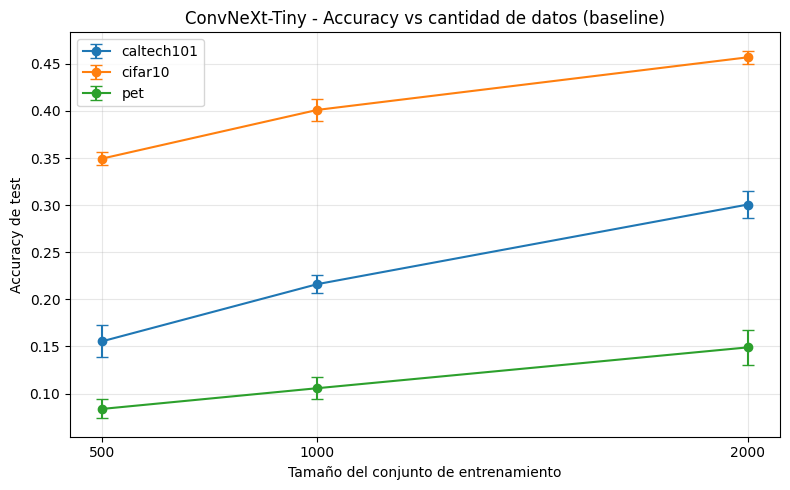

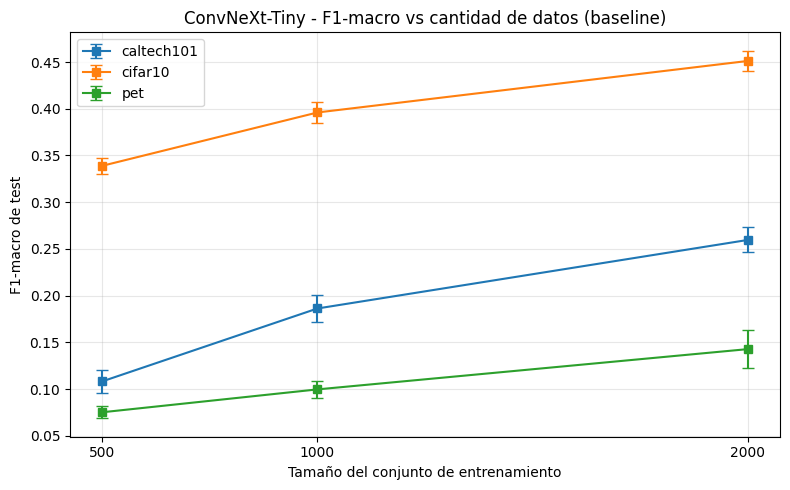

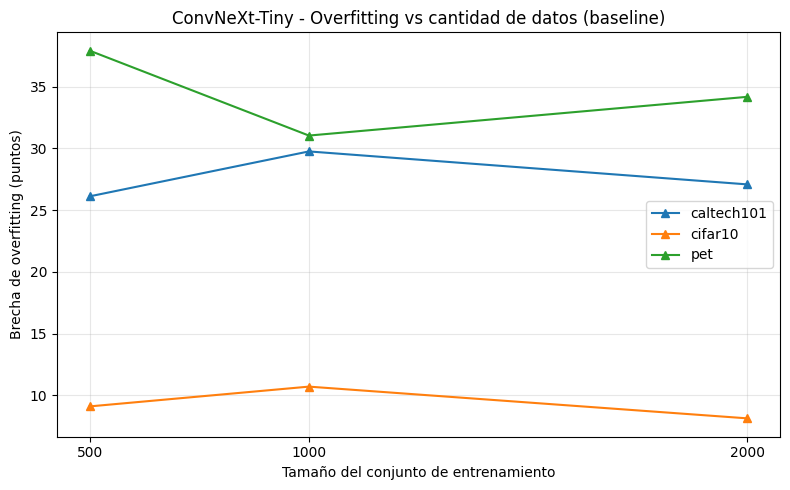

In [28]:
# análisis de resultados (FASE 1: baseline)
import pandas as pd
import matplotlib.pyplot as plt

# Carga el CSV del modelo
df = pd.read_csv(RESULTS_DIR / "resultados_cnn.csv")

# compatibilidad con csv antiguos que no tenian la columna aug
if "aug" not in df.columns:
    df["aug"] = 0

# OJO: el dedupe DEBE incluir "aug". Si no, una corrida de Fase 2 (aug=1)
# borraria a su gemela baseline (aug=0) con el mismo dataset/tamaño/semilla.
df = df.drop_duplicates(subset=["model","dataset","train_size","seed","aug"],
                        keep="last")

n_aug = int((df["aug"] == 1).sum())
print(f"Filas cargadas: {len(df)} "
      f"(baseline aug=0: {int((df['aug']==0).sum())} | fase 2 aug=1: {n_aug})")
if n_aug:
    print("(las corridas con aug=1 se analizan en la sección 10; "
          "aquí solo se grafica el baseline)")

base_df = df[df["aug"] == 0]
print(base_df[["dataset","train_size","seed","test_acc","test_f1_macro",
               "overfitting_gap"]])


def resumir(d):
    """media ± std sobre las 3 semillas, por dataset y tamaño"""
    return (d.groupby(["dataset","train_size"])
             .agg(acc_media=("test_acc","mean"),  acc_std=("test_acc","std"),
                  f1_media=("test_f1_macro","mean"), f1_std=("test_f1_macro","std"),
                  of_media=("overfitting_gap","mean"))
             .reset_index())

resumen = resumir(base_df)
print("\nResumen BASELINE (media ± std por dataset y tamaño):")
print(resumen.round(4))


# gráfico 1: accuracy vs tamaño de dataset
# Gráfico principal. Una línea por dataset, con barras de error (std).
plt.figure(figsize=(8, 5))
for ds in resumen["dataset"].unique():
    sub = resumen[resumen["dataset"] == ds].sort_values("train_size")
    plt.errorbar(sub["train_size"], sub["acc_media"], yerr=sub["acc_std"],
                 marker="o", capsize=4, label=ds)
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("Accuracy de test")
plt.title("ConvNeXt-Tiny - Accuracy vs cantidad de datos (baseline)")
plt.xticks(sorted(df["train_size"].unique()))
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()


# gráfico 2: f1-macro vs tamaño
# Útil sobre todo para Caltech-101, por el desbalance de clases.
plt.figure(figsize=(8, 5))
for ds in resumen["dataset"].unique():
    sub = resumen[resumen["dataset"] == ds].sort_values("train_size")
    plt.errorbar(sub["train_size"], sub["f1_media"], yerr=sub["f1_std"],
                 marker="s", capsize=4, label=ds)
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("F1-macro de test")
plt.title("ConvNeXt-Tiny - F1-macro vs cantidad de datos (baseline)")
plt.xticks(sorted(df["train_size"].unique()))
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()


# gráfico 3: brecha de overfitting vs tamaño — SOLO baseline.
# con aug=1 el train_acc se mide contra una etiqueta mezclada (y_a), asi que
# el gap de esas corridas no es comparable y no se grafica aqui.
plt.figure(figsize=(8, 5))
for ds in resumen["dataset"].unique():
    sub = resumen[resumen["dataset"] == ds].sort_values("train_size")
    plt.plot(sub["train_size"], sub["of_media"], marker="^", label=ds)
plt.xlabel("Tamaño del conjunto de entrenamiento")
plt.ylabel("Brecha de overfitting (puntos)")
plt.title("ConvNeXt-Tiny - Overfitting vs cantidad de datos (baseline)")
plt.xticks(sorted(df["train_size"].unique()))
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()

### Matriz de confusión

Matriz de confusión sobre el conjunto de test: la diagonal son los aciertos y el resto, las confusiones entre clases. Se calcula a partir de las predicciones guardadas al entrenar (`predicciones/`), así que no hace falta reentrenar. En Oxford Pet (37 clases) y Caltech-101 (101 clases) se muestran solo las clases con más errores, porque la matriz completa sería ilegible.

In [29]:
# matriz de confusión
import numpy as np
import matplotlib.pyplot as plt

def _nombres_clases(dataset_name):
    # intenta sacar los nombres reales de las clases (solo lee metadatos,
    # no entrena). si falla, devuelve None y se usan los numeros de clase.
    try:
        transform = next(iter(MODELOS.values()))["transform"](dataset_name, train=False)
        ds, _ = _cargar_dataset_base(dataset_name, transform)
        base = ds.dataset if hasattr(ds, "dataset") else ds
        if dataset_name == "caltech101":
            cats = list(getattr(base, "categories", []))
            return [c for c in cats if c != "BACKGROUND_Google"]
        return list(getattr(base, "classes", [])) or None
    except Exception:
        return None


def _preds_para_matriz(model_key, dataset_name, train_size, seed, use_aug):
    # 1) si hay predicciones guardadas, las usa (rapido, sin entrenar)
    p = cargar_preds(model_key, dataset_name, train_size, seed, use_aug)
    if p is not None:
        print(f"predicciones cargadas de disco ({dataset_name}, size={train_size})")
        return np.array(p[0]), np.array(p[1])
    # 2) si no, entrena esa combinacion (y de paso guarda todo en el csv/preds)
    print(f"no hay predicciones guardadas, entrenando {model_key}/{dataset_name}...")
    correr_uno(model_key, dataset_name, train_size, seed,
               use_aug=use_aug, verbose=False, forzar=True)
    p = cargar_preds(model_key, dataset_name, train_size, seed, use_aug)
    return np.array(p[0]), np.array(p[1])


def matriz_confusion(model_key, dataset_name, train_size, seed,
                     top_n=15, normalizar=True, usar_nombres=True, use_aug=False):
    """dibuja la matriz de confusion de una combinacion. usa las predicciones
    guardadas si existen; si no, entrena esa combinacion una vez."""
    num_classes = NUM_CLASSES[dataset_name]
    y_true, y_pred = _preds_para_matriz(model_key, dataset_name,
                                        train_size, seed, use_aug)

    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1

    nombres = _nombres_clases(dataset_name) if usar_nombres else None
    def etiqueta(c):
        if nombres and c < len(nombres):
            return str(nombres[c])[:18]
        return str(c)

    clases_presentes = sorted(set(y_true.tolist()))
    if len(clases_presentes) > top_n:
        errores = []
        for c in clases_presentes:
            err = cm[c].sum() - cm[c, c]
            errores.append((err, c))
        errores.sort(reverse=True)
        clases_mostrar = sorted([c for _, c in errores[:top_n]])
        titulo_extra = f" (top {top_n} clases con mas errores)"
    else:
        clases_mostrar = clases_presentes
        titulo_extra = ""

    cm_sub = cm[np.ix_(clases_mostrar, clases_mostrar)]
    if normalizar:
        filas = cm_sub.sum(axis=1, keepdims=True); filas[filas == 0] = 1
        cm_plot = cm_sub / filas; fmt = ".2f"
    else:
        cm_plot = cm_sub; fmt = "d"

    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(cm_plot, cmap="Blues", vmin=0, vmax=1 if normalizar else None)
    labels = [etiqueta(c) for c in clases_mostrar]
    ax.set_xticks(range(len(clases_mostrar))); ax.set_yticks(range(len(clases_mostrar)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    ax.set_title(f"Matriz de confusion - {model_key} / {dataset_name} "
                 f"(size={train_size}){titulo_extra}")
    plt.colorbar(im, ax=ax, fraction=0.046)

    if len(clases_mostrar) <= 12:
        umbral = 0.5 if normalizar else cm_plot.max() / 2
        for i in range(len(clases_mostrar)):
            for j in range(len(clases_mostrar)):
                v = cm_plot[i, j]
                ax.text(j, i, format(v, fmt), ha="center", va="center",
                        color="white" if v > umbral else "black", fontsize=7)

    plt.tight_layout(); plt.show()
    return cm


# ejemplos. la primera vez entrena (si no hay preds guardadas); despues carga.
# matriz_confusion("cnn", "cifar10", train_size=2000, seed=42)
# matriz_confusion("cnn", "caltech101", train_size=2000, seed=42)
# matriz_confusion("cnn", "pet", train_size=2000, seed=42)

In [30]:
# matriz de confusión por DATASET (junta las 3 semillas de la mejor config)
# genera UNA matriz por dataset en vez de una por combinacion. usa las
# predicciones ya guardadas de las 3 semillas; NO reentrena si existen.

def matriz_confusion_dataset(model_key, dataset_name, train_size=2000,
                             seeds=None, top_n=15, normalizar=True,
                             usar_nombres=True, use_aug=False):
    """Una matriz de confusion para un dataset, agregando las predicciones de
    las 3 semillas de la config `train_size` (por defecto 2000, la mejor).
    Junta los y_true/y_pred de cada semilla -> matriz mas robusta (3x mas
    ejemplos de test, sin depender de una sola corrida). Reutiliza el ploteo
    de matriz_confusion. Si a alguna semilla le faltan predicciones, la entrena
    una vez (forzar) para completarlas."""
    if seeds is None:
        seeds = SEEDS

    num_classes = NUM_CLASSES[dataset_name]
    y_true_all, y_pred_all = [], []
    usadas = []
    for seed in seeds:
        p = cargar_preds(model_key, dataset_name, train_size, seed, use_aug)
        if p is None:
            print(f"  falta pred de seed={seed}, entrenando esa combinacion...")
            correr_uno(model_key, dataset_name, train_size, seed,
                       use_aug=use_aug, verbose=False, forzar=True)
            p = cargar_preds(model_key, dataset_name, train_size, seed, use_aug)
        y_true_all.append(np.array(p[0]))
        y_pred_all.append(np.array(p[1]))
        usadas.append(seed)

    y_true = np.concatenate(y_true_all)
    y_pred = np.concatenate(y_pred_all)
    print(f"{dataset_name}: matriz sobre {len(usadas)} semillas {usadas} "
          f"(size={train_size}) -> {len(y_true)} predicciones de test")

    # construir matriz completa
    cm = np.zeros((num_classes, num_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1

    # --- de aqui en adelante, mismo ploteo que matriz_confusion ---
    nombres = _nombres_clases(dataset_name) if usar_nombres else None
    def etiqueta(c):
        if nombres and c < len(nombres):
            return str(nombres[c])[:18]
        return str(c)

    clases_presentes = sorted(set(y_true.tolist()))
    if len(clases_presentes) > top_n:
        errores = []
        for c in clases_presentes:
            errores.append((cm[c].sum() - cm[c, c], c))
        errores.sort(reverse=True)
        clases_mostrar = sorted([c for _, c in errores[:top_n]])
        titulo_extra = f" (top {top_n} clases con mas errores)"
    else:
        clases_mostrar = clases_presentes
        titulo_extra = ""

    cm_sub = cm[np.ix_(clases_mostrar, clases_mostrar)]
    if normalizar:
        filas = cm_sub.sum(axis=1, keepdims=True); filas[filas == 0] = 1
        cm_plot = cm_sub / filas; fmt = ".2f"
    else:
        cm_plot = cm_sub; fmt = "d"

    fig, ax = plt.subplots(figsize=(10, 9))
    im = ax.imshow(cm_plot, cmap="Blues", vmin=0, vmax=1 if normalizar else None)
    labels = [etiqueta(c) for c in clases_mostrar]
    ax.set_xticks(range(len(clases_mostrar))); ax.set_yticks(range(len(clases_mostrar)))
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticklabels(labels, fontsize=7)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    ax.set_title(f"Matriz de confusion - {model_key} / {dataset_name} "
                 f"(size={train_size}, {len(usadas)} semillas){titulo_extra}")
    plt.colorbar(im, ax=ax, fraction=0.046)

    if len(clases_mostrar) <= 12:
        umbral = 0.5 if normalizar else cm_plot.max() / 2
        for i in range(len(clases_mostrar)):
            for j in range(len(clases_mostrar)):
                v = cm_plot[i, j]
                ax.text(j, i, format(v, fmt), ha="center", va="center",
                        color="white" if v > umbral else "black", fontsize=7)

    plt.tight_layout(); plt.show()
    return cm


def matrices_todos_los_datasets(model_key="cnn", train_size=2000,
                                use_aug=False):
    """Genera las 3 matrices (una por dataset) de una sola llamada.
    El resultado para el paper: 3 matrices, cada una en la mejor config,
    agregando las 3 semillas."""
    cms = {}
    for ds in ["cifar10", "pet", "caltech101"]:
        cms[ds] = matriz_confusion_dataset(model_key, ds, train_size=train_size,
                                           use_aug=use_aug)
    return cms


# --- USO ---
# las tres juntas:
#   matrices_todos_los_datasets("cnn")
# o una sola:
#   matriz_confusion_dataset("cnn", "caltech101")

## 10. Fase 2: data augmentation (RandAugment + MixUp/CutMix)

Mismo protocolo que la Fase 1, agregando augmentation solo sobre el conjunto de entrenamiento:

- **RandAugment** (por imagen): aplica 2 transformaciones aleatorias por imagen (rotación, color, contraste, etc.) con magnitud 9.
- **MixUp** (por batch): mezcla linealmente pares de imágenes y sus etiquetas (por ejemplo, `0.7·gato + 0.3·perro`).
- **CutMix** (por batch): pega un parche rectangular de una imagen sobre otra y reparte la etiqueta según el área.

Dónde está implementada cada pieza:
- RandAugment, en la transform del modelo (sección 6, `if train:`).
- El motor de entrenamiento (sección 5) acepta etiquetas mezcladas (*soft labels*).
- El collate de MixUp/CutMix se define aquí y se conecta en `obtener_loaders` (sección 4).

**Nota metodológica:** con `aug=1`, el `train_acc` se mide contra una de las dos etiquetas mezcladas, así que la brecha de sobreajuste **no es comparable** con la del baseline. La comparación entre fases se hace con `test_acc` y F1-macro (validación y test nunca se mezclan).

In [32]:
# FASE 2 - definiciones: MixUp/CutMix a nivel de batch
# (RandAugment no necesita nada aquí: ya está implementado en la transform.)

MIXUP_ALPHA = 0.2   # Beta(0.2,0.2): mezclas suaves, tipico en fine-tuning
CUTMIX_ALPHA = 1.0  # Beta(1,1)=uniforme: recortes de tamaño variado
PROB_CUTMIX = 0.5   # 50% de los batches usan CutMix; el resto, MixUp


def _rand_bbox(H, W, lam, rng_np):
    """Caja rectangular para CutMix, área proporcional a (1-lam)."""
    ratio = np.sqrt(1.0 - lam)
    cut_w, cut_h = int(W * ratio), int(H * ratio)
    cx, cy = rng_np.randint(W), rng_np.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    y2 = np.clip(cy + cut_h // 2, 0, H)
    return x1, y1, x2, y2


def mixup_cutmix_collate(batch):
    """Apila el batch (como el collate por defecto) y luego aplica MixUp o
    CutMix. Devuelve (X, y_a, y_b, lam): la pérdida será
    lam*loss(out,y_a) + (1-lam)*loss(out,y_b)."""
    xs = torch.stack([b[0] for b in batch])
    ys = torch.tensor([b[1] for b in batch])

    # RNG local de numpy sembrado desde el RNG global de torch (ya fijado por
    # fijar_semilla). Como num_workers=0, el collate corre en el proceso
    # principal y la secuencia es determinista -> reproducible por semilla.
    # (El sorteo consume del RNG de torch, igual que el randperm de abajo.)
    rng_np = np.random.RandomState(int(torch.randint(0, 2**31 - 1, (1,)).item()))

    perm = torch.randperm(xs.size(0))
    y_a, y_b = ys, ys[perm]

    if rng_np.rand() < PROB_CUTMIX:
        lam = rng_np.beta(CUTMIX_ALPHA, CUTMIX_ALPHA)
        H, W = xs.shape[-2], xs.shape[-1]
        x1, y1, x2, y2 = _rand_bbox(H, W, lam, rng_np)
        xs[:, :, y1:y2, x1:x2] = xs[perm, :, y1:y2, x1:x2]
        # lam real = fracción de píxeles que quedaron de la imagen original
        lam = 1.0 - ((x2 - x1) * (y2 - y1) / (H * W))
    else:
        lam = rng_np.beta(MIXUP_ALPHA, MIXUP_ALPHA)
        xs = lam * xs + (1.0 - lam) * xs[perm]

    return xs, y_a, y_b, float(lam)


print("Collate de MixUp/CutMix definido: ya puedes usar use_aug=True.")

Collate de MixUp/CutMix definido: ya puedes usar use_aug=True.


In [33]:
# Fase 2: con augmentation (RandAugment + MixUp/CutMix)

# Prueba corta: valida el entrenamiento con etiquetas mezcladas y que la
# fila quede guardada con aug=1.
fila_aug, res_aug = correr_uno("cnn", "cifar10", 1000, 42, use_aug=True)

# Grilla completa: 3 tamaños x 3 semillas por dataset. Los experimentos que
# ya están en el CSV se cargan en vez de reentrenarse.
correr_grid("cnn", "caltech101", use_aug=True)
correr_grid("cnn", "pet", use_aug=True)
correr_grid("cnn", "cifar10", use_aug=True)

[saltado] cnn | cifar10 | size=1000 | seed=42 | aug=1  ->  test_acc=0.357 (cargado del CSV)
[saltado] cnn | caltech101 | size=500 | seed=42 | aug=1  ->  test_acc=0.0625 (cargado del CSV)
[saltado] cnn | caltech101 | size=500 | seed=123 | aug=1  ->  test_acc=0.0485 (cargado del CSV)
[saltado] cnn | caltech101 | size=500 | seed=2024 | aug=1  ->  test_acc=0.06 (cargado del CSV)
[saltado] cnn | caltech101 | size=1000 | seed=42 | aug=1  ->  test_acc=0.1195 (cargado del CSV)
[saltado] cnn | caltech101 | size=1000 | seed=123 | aug=1  ->  test_acc=0.0935 (cargado del CSV)
[saltado] cnn | caltech101 | size=1000 | seed=2024 | aug=1  ->  test_acc=0.11 (cargado del CSV)
[saltado] cnn | caltech101 | size=2000 | seed=42 | aug=1  ->  test_acc=0.1705 (cargado del CSV)
[saltado] cnn | caltech101 | size=2000 | seed=123 | aug=1  ->  test_acc=0.16 (cargado del CSV)
[saltado] cnn | caltech101 | size=2000 | seed=2024 | aug=1  ->  test_acc=0.18 (cargado del CSV)
[saltado] cnn | pet | size=500 | seed=42 | aug

[{'model': 'cnn',
  'dataset': 'cifar10',
  'train_size': '500',
  'seed': '42',
  'aug': '1',
  'test_acc': '0.302',
  'test_f1_macro': '0.2817',
  'val_acc': '0.292',
  'train_acc_final': '0.152',
  'overfitting_gap': '-15.0',
  'n_params': '620362',
  'n_train': '500',
  'n_val': '1000',
  'n_test': '2000',
  'epochs': '20',
  'train_time_s': '27.7',
  'device': 'cpu',
  'timestamp': '2026-07-08T03:29:07'},
 {'model': 'cnn',
  'dataset': 'cifar10',
  'train_size': '500',
  'seed': '123',
  'aug': '1',
  'test_acc': '0.3225',
  'test_f1_macro': '0.2915',
  'val_acc': '0.301',
  'train_acc_final': '0.202',
  'overfitting_gap': '-12.05',
  'n_params': '620362',
  'n_train': '500',
  'n_val': '1000',
  'n_test': '2000',
  'epochs': '20',
  'train_time_s': '26.8',
  'device': 'cpu',
  'timestamp': '2026-07-08T03:29:37'},
 {'model': 'cnn',
  'dataset': 'cifar10',
  'train_size': '500',
  'seed': '2024',
  'aug': '1',
  'test_acc': '0.307',
  'test_f1_macro': '0.2798',
  'val_acc': '0.323'

Resumen FASE 2 (aug=1):
      dataset  train_size  acc_media  acc_std  f1_media  f1_std
0  caltech101         500     0.0570   0.0075    0.0175  0.0046
1  caltech101        1000     0.1077   0.0132    0.0665  0.0086
2  caltech101        2000     0.1702   0.0100    0.1124  0.0023
3     cifar10         500     0.3105   0.0107    0.2843  0.0063
4     cifar10        1000     0.3718   0.0129    0.3560  0.0172
5     cifar10        2000     0.4317   0.0071    0.4228  0.0143
6         pet         500     0.0750   0.0096    0.0511  0.0091
7         pet        1000     0.1053   0.0232    0.0823  0.0168
8         pet        2000     0.1317   0.0064    0.1110  0.0073

Efecto del augmentation (aug − baseline):
   dataset  train_size  acc_media_base  acc_media_aug  delta_acc  delta_f1
caltech101         500        0.155500       0.057000    -0.0985   -0.0908
caltech101        1000        0.216167       0.107667    -0.1085   -0.1197
caltech101        2000        0.300667       0.170167    -0.1305   -

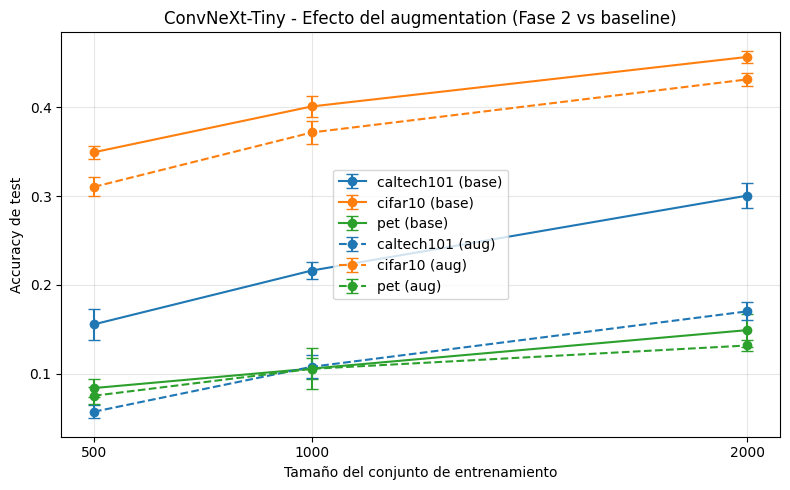

In [34]:
# FASE 2 - análisis: efecto del augmentation vs baseline
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(RESULTS_DIR / "resultados_cnn.csv")
if "aug" not in df.columns:
    df["aug"] = 0
df = df.drop_duplicates(subset=["model","dataset","train_size","seed","aug"],
                        keep="last")

con_aug = df[df["aug"] == 1]
if not len(con_aug):
    print("Aún no hay corridas con aug=1: corre las grillas de arriba primero.")
else:
    def resumir(d):
        return (d.groupby(["dataset","train_size"])
                 .agg(acc_media=("test_acc","mean"),  acc_std=("test_acc","std"),
                      f1_media=("test_f1_macro","mean"), f1_std=("test_f1_macro","std"))
                 .reset_index())

    base = resumir(df[df["aug"] == 0])
    aug  = resumir(con_aug)
    print("Resumen FASE 2 (aug=1):")
    print(aug.round(4))

    # tabla de efecto: cuánto suma (o resta) el augmentation
    m = base.merge(aug, on=["dataset","train_size"], suffixes=("_base","_aug"))
    m["delta_acc"] = (m["acc_media_aug"] - m["acc_media_base"]).round(4)
    m["delta_f1"]  = (m["f1_media_aug"]  - m["f1_media_base"]).round(4)
    print("\nEfecto del augmentation (aug − baseline):")
    print(m[["dataset","train_size","acc_media_base","acc_media_aug",
             "delta_acc","delta_f1"]].to_string(index=False))

    # gráfico: accuracy baseline (línea llena) vs aug (punteada), por dataset
    plt.figure(figsize=(8, 5))
    colores = {}
    for ds in base["dataset"].unique():
        sub = base[base["dataset"] == ds].sort_values("train_size")
        cont = plt.errorbar(sub["train_size"], sub["acc_media"],
                            yerr=sub["acc_std"], marker="o", capsize=4,
                            label=f"{ds} (base)")
        colores[ds] = cont.lines[0].get_color()
    for ds in aug["dataset"].unique():
        sub = aug[aug["dataset"] == ds].sort_values("train_size")
        plt.errorbar(sub["train_size"], sub["acc_media"], yerr=sub["acc_std"],
                     marker="o", capsize=4, linestyle="--",
                     color=colores.get(ds), label=f"{ds} (aug)")
    plt.xlabel("Tamaño del conjunto de entrenamiento")
    plt.ylabel("Accuracy de test")
    plt.title("ConvNeXt-Tiny - Efecto del augmentation (Fase 2 vs baseline)")
    plt.xticks(sorted(df["train_size"].unique()))
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.show()

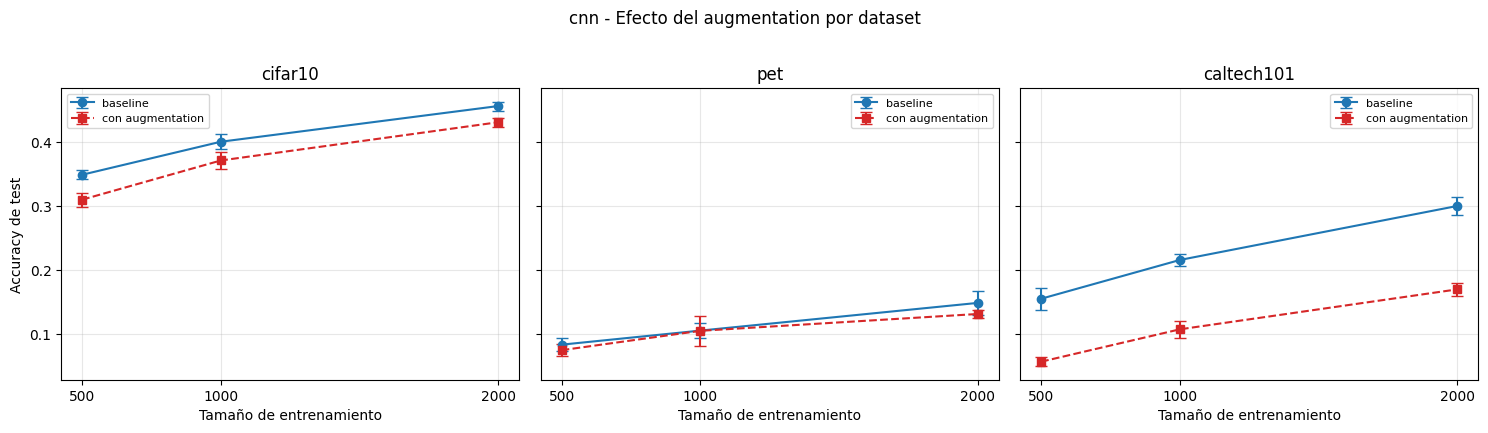


Delta de accuracy (aug - baseline) por dataset y tamaño:
  cifar10     size=  500 : -0.0390
  cifar10     size= 1000 : -0.0293
  cifar10     size= 2000 : -0.0253
  pet         size=  500 : -0.0087
  pet         size= 1000 : -0.0003
  pet         size= 2000 : -0.0173
  caltech101  size=  500 : -0.0985
  caltech101  size= 1000 : -0.1085
  caltech101  size= 2000 : -0.1305


In [35]:
# FASE 2 - gráficos SEPARADOS: uno por dataset (baseline vs aug)
# más legible que el gráfico conjunto: cada dataset en su propio panel,
# baseline (línea llena) vs aug (punteada), con barras de error (std).

def graficos_aug_por_dataset(model_key="cnn"):
    import pandas as pd
    import matplotlib.pyplot as plt

    df = pd.read_csv(RESULTS_DIR / f"resultados_{model_key}.csv")
    if "aug" not in df.columns:
        df["aug"] = 0
    df = df.drop_duplicates(subset=["model","dataset","train_size","seed","aug"],
                            keep="last")
    if not len(df[df["aug"] == 1]):
        print("Aún no hay corridas con aug=1.")
        return

    def resumir(d):
        return (d.groupby("train_size")
                 .agg(acc=("test_acc","mean"), std=("test_acc","std"),
                      f1=("test_f1_macro","mean"))
                 .reset_index().sort_values("train_size"))

    datasets = ["cifar10", "pet", "caltech101"]
    presentes = [ds for ds in datasets if len(df[df["dataset"] == ds])]

    # una fila de paneles, uno por dataset
    fig, axes = plt.subplots(1, len(presentes), figsize=(5*len(presentes), 4.2),
                             sharey=True)
    if len(presentes) == 1:
        axes = [axes]

    for ax, ds in zip(axes, presentes):
        base = resumir(df[(df["dataset"] == ds) & (df["aug"] == 0)])
        aug  = resumir(df[(df["dataset"] == ds) & (df["aug"] == 1)])

        ax.errorbar(base["train_size"], base["acc"], yerr=base["std"],
                    marker="o", capsize=4, color="tab:blue", label="baseline")
        ax.errorbar(aug["train_size"], aug["acc"], yerr=aug["std"],
                    marker="s", capsize=4, linestyle="--", color="tab:red",
                    label="con augmentation")
        ax.set_title(ds)
        ax.set_xlabel("Tamaño de entrenamiento")
        ax.set_xticks(sorted(df["train_size"].unique()))
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Accuracy de test")
    fig.suptitle(f"{model_key} - Efecto del augmentation por dataset", y=1.02)
    plt.tight_layout(); plt.show()

    # tabla resumen del delta por dataset y tamaño
    print("\nDelta de accuracy (aug - baseline) por dataset y tamaño:")
    for ds in presentes:
        base = resumir(df[(df["dataset"] == ds) & (df["aug"] == 0)]).set_index("train_size")
        aug  = resumir(df[(df["dataset"] == ds) & (df["aug"] == 1)]).set_index("train_size")
        for ts in sorted(set(base.index) & set(aug.index)):
            d = aug.loc[ts,"acc"] - base.loc[ts,"acc"]
            signo = "+" if d >= 0 else ""
            print(f"  {ds:11} size={ts:5} : {signo}{d:.4f}")


graficos_aug_por_dataset("cnn")